# 04 — Final journal tables and figures

Generates clean publication-oriented tables and comparison figures from the completed OOF and locked-test result bundles.

This notebook does not train or tune any model. It only summarizes frozen results.

In [1]:

from pathlib import Path
import io
import json
import math
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

print("Python analysis environment ready.")


Python analysis environment ready.


In [2]:

def _json_load_bytes(raw):
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")
    return json.loads(raw)


def _bundle_candidates(metadata_filename, expected_model):
    """
    Finds a result bundle either as:
    1) a ZIP somewhere under /kaggle/input, or
    2) an already-extracted Kaggle dataset directory.
    """
    candidates = []

    # ZIP bundles.
    for zpath in INPUT_ROOT.rglob("*.zip"):
        try:
            with zipfile.ZipFile(zpath, "r") as zf:
                names = zf.namelist()
                if metadata_filename not in names:
                    continue
                meta = _json_load_bytes(zf.read(metadata_filename))
                if str(meta.get("model", "")) == expected_model:
                    candidates.append({
                        "kind": "zip",
                        "source": zpath,
                        "metadata": meta,
                        "metadata_filename": metadata_filename,
                    })
        except zipfile.BadZipFile:
            continue

    # Extracted bundles.
    for mpath in INPUT_ROOT.rglob(metadata_filename):
        try:
            meta = json.loads(mpath.read_text(encoding="utf-8"))
        except Exception:
            continue
        if str(meta.get("model", "")) == expected_model:
            candidates.append({
                "kind": "dir",
                "source": mpath.parent,
                "metadata": meta,
                "metadata_filename": metadata_filename,
            })

    if not candidates:
        raise FileNotFoundError(
            f"Could not find result bundle for model={expected_model!r}. "
            f"Attach the corresponding result ZIP to Kaggle."
        )

    # If the same bundle is attached more than once, choose the first
    # deterministic candidate and print a warning.
    candidates = sorted(candidates, key=lambda x: str(x["source"]))
    if len(candidates) > 1:
        print(
            f"Warning: found {len(candidates)} matching bundles for "
            f"{expected_model}; using {candidates[0]['source']}"
        )

    bundle = candidates[0]

    split_hash = bundle["metadata"].get("split_sha256")
    if split_hash is not None and split_hash != EXPECTED_SPLIT_SHA256:
        raise RuntimeError(
            f"Frozen split hash mismatch for {expected_model}: {split_hash}"
        )

    return bundle


def _read_csv_from_bundle(bundle, required_suffix):
    if bundle["kind"] == "zip":
        with zipfile.ZipFile(bundle["source"], "r") as zf:
            hits = [
                name for name in zf.namelist()
                if name.endswith(required_suffix)
            ]
            if len(hits) != 1:
                raise FileNotFoundError(
                    f"Expected exactly one *{required_suffix} inside "
                    f"{bundle['source']}, found {hits}"
                )
            return pd.read_csv(zf.open(hits[0]))

    hits = list(bundle["source"].rglob(f"*{required_suffix}"))
    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one *{required_suffix} under "
            f"{bundle['source']}, found {hits}"
        )
    return pd.read_csv(hits[0])


def _read_optional_csv_from_bundle(bundle, required_suffix):
    try:
        return _read_csv_from_bundle(bundle, required_suffix)
    except Exception:
        return None


def load_oof_model(expected_model):
    bundle = _bundle_candidates(
        "evaluation_metadata.json",
        expected_model,
    )
    df = _read_csv_from_bundle(bundle, "patient_metrics.csv").copy()

    if len(df) != 80 or df["patient_id"].nunique() != 80:
        raise RuntimeError(
            f"{expected_model}: expected 80 unique OOF patients, "
            f"found rows={len(df)}, unique={df['patient_id'].nunique()}."
        )

    if "fold" not in df.columns:
        raise RuntimeError(f"{expected_model}: OOF patient file has no fold column.")

    if bundle["metadata"].get("locked_test_evaluated") not in (False, None):
        raise RuntimeError(
            f"{expected_model}: OOF metadata says locked test was evaluated."
        )

    df["patient_id"] = df["patient_id"].astype(int)
    df = df.sort_values("patient_id").reset_index(drop=True)
    return bundle, df


def load_test_model(expected_model):
    bundle = _bundle_candidates(
        "final_locked_test_metadata.json",
        expected_model,
    )
    df = _read_csv_from_bundle(bundle, "patient_metrics.csv").copy()

    if len(df) != 20 or df["patient_id"].nunique() != 20:
        raise RuntimeError(
            f"{expected_model}: expected 20 unique locked-test patients, "
            f"found rows={len(df)}, unique={df['patient_id'].nunique()}."
        )

    df["patient_id"] = df["patient_id"].astype(int)
    df = df.sort_values("patient_id").reset_index(drop=True)
    return bundle, df


def assert_same_patients(reference_df, comparison_df, label):
    ref_ids = reference_df["patient_id"].astype(int).tolist()
    cmp_ids = comparison_df["patient_id"].astype(int).tolist()
    if ref_ids != cmp_ids:
        raise RuntimeError(
            f"Patient IDs/order do not match for {label}."
        )


def assert_same_oof_folds(reference_df, comparison_df, label):
    merged = reference_df[["patient_id", "fold"]].merge(
        comparison_df[["patient_id", "fold"]],
        on="patient_id",
        suffixes=("_reference", "_comparison"),
        validate="one_to_one",
    )
    if not np.array_equal(
        merged["fold_reference"].to_numpy(),
        merged["fold_comparison"].to_numpy(),
    ):
        raise RuntimeError(f"OOF fold assignments differ for {label}.")


In [3]:

METRICS = {
    "mean_foreground_dice": {
        "label": "Mean foreground Dice",
        "higher_is_better": True,
    },
    "ventricle_dice": {
        "label": "Ventricle Dice",
        "higher_is_better": True,
    },
    "normal_wmh_dice": {
        "label": "Normal-WMH Dice",
        "higher_is_better": True,
    },
    "abnormal_wmh_dice": {
        "label": "Abnormal-WMH Dice",
        "higher_is_better": True,
    },
    "normal_wmh_lesion_f1": {
        "label": "Normal-WMH lesion F1",
        "higher_is_better": True,
    },
    "abnormal_wmh_lesion_f1": {
        "label": "Abnormal-WMH lesion F1",
        "higher_is_better": True,
    },
    "periventricular_abnormal_fp_rate": {
        "label": "Periventricular abnormal FP rate",
        "higher_is_better": False,
    },
}


def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adjusted_sorted = np.empty(n, dtype=float)

    running = 0.0
    for rank, idx in enumerate(order):
        value = (n - rank) * p[idx]
        running = max(running, value)
        adjusted_sorted[rank] = min(running, 1.0)

    adjusted = np.empty(n, dtype=float)
    for rank, idx in enumerate(order):
        adjusted[idx] = adjusted_sorted[rank]
    return adjusted


def paired_bootstrap_mean_ci(diff, repeats=20000, seed=42):
    diff = np.asarray(diff, dtype=float)
    diff = diff[np.isfinite(diff)]
    if len(diff) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    idx = rng.integers(
        0,
        len(diff),
        size=(repeats, len(diff)),
        endpoint=False,
    )
    means = diff[idx].mean(axis=1)
    return (
        float(np.percentile(means, 2.5)),
        float(np.percentile(means, 97.5)),
    )


def rank_biserial_from_paired_difference(benefit_diff):
    """
    Matched-pairs rank-biserial correlation.
    Positive means the reference model is better.
    """
    d = np.asarray(benefit_diff, dtype=float)
    d = d[np.isfinite(d)]
    d = d[d != 0]

    if len(d) == 0:
        return 0.0

    ranks = stats.rankdata(np.abs(d), method="average")
    w_plus = float(ranks[d > 0].sum())
    w_minus = float(ranks[d < 0].sum())
    denom = w_plus + w_minus
    return 0.0 if denom == 0 else (w_plus - w_minus) / denom


def cohen_dz(benefit_diff):
    d = np.asarray(benefit_diff, dtype=float)
    d = d[np.isfinite(d)]
    if len(d) < 2:
        return np.nan
    sd = d.std(ddof=1)
    if sd == 0:
        return np.nan
    return float(d.mean() / sd)


def paired_comparison_rows(
    reference_df,
    comparison_df,
    reference_name,
    comparison_name,
    bootstrap_repeats=20000,
    seed=42,
):
    assert_same_patients(reference_df, comparison_df, comparison_name)

    rows = []

    for metric, info in METRICS.items():
        ref = pd.to_numeric(reference_df[metric], errors="coerce").to_numpy(float)
        cmp = pd.to_numeric(comparison_df[metric], errors="coerce").to_numpy(float)

        finite = np.isfinite(ref) & np.isfinite(cmp)
        ref = ref[finite]
        cmp = cmp[finite]

        raw_diff = ref - cmp
        benefit_diff = raw_diff if info["higher_is_better"] else -raw_diff

        if len(benefit_diff) == 0:
            continue

        # Wilcoxon signed-rank is pre-specified for paired patient-level comparison.
        try:
            wilcoxon = stats.wilcoxon(
                benefit_diff,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto",
            )
            p_value = float(wilcoxon.pvalue)
            statistic = float(wilcoxon.statistic)
        except ValueError:
            p_value = 1.0
            statistic = 0.0

        ci_low, ci_high = paired_bootstrap_mean_ci(
            benefit_diff,
            repeats=bootstrap_repeats,
            seed=seed,
        )

        wins = int(np.sum(benefit_diff > 0))
        ties = int(np.sum(benefit_diff == 0))
        losses = int(np.sum(benefit_diff < 0))

        rows.append({
            "reference_model": reference_name,
            "comparison_model": comparison_name,
            "metric": metric,
            "metric_label": info["label"],
            "higher_is_better": info["higher_is_better"],
            "n_paired": int(len(benefit_diff)),
            "reference_mean": float(np.mean(ref)),
            "comparison_mean": float(np.mean(cmp)),
            "raw_mean_difference_reference_minus_comparison": float(np.mean(raw_diff)),
            "benefit_mean_difference_positive_favors_reference": float(np.mean(benefit_diff)),
            "benefit_bootstrap_95ci_low": ci_low,
            "benefit_bootstrap_95ci_high": ci_high,
            "wilcoxon_statistic": statistic,
            "wilcoxon_p_raw": p_value,
            "rank_biserial_positive_favors_reference": float(
                rank_biserial_from_paired_difference(benefit_diff)
            ),
            "cohen_dz_positive_favors_reference": cohen_dz(benefit_diff),
            "reference_wins": wins,
            "ties": ties,
            "comparison_wins": losses,
        })

    return pd.DataFrame(rows)


def add_holm_by_metric(stats_df):
    out = stats_df.copy()
    out["wilcoxon_p_holm"] = np.nan

    for metric, idx in out.groupby("metric").groups.items():
        idx = list(idx)
        out.loc[idx, "wilcoxon_p_holm"] = holm_adjust(
            out.loc[idx, "wilcoxon_p_raw"].to_numpy(float)
        )

    out["significant_holm_0_05"] = out["wilcoxon_p_holm"] < 0.05
    return out


def model_summary_table(model_frames, metric_names=None):
    if metric_names is None:
        metric_names = list(METRICS.keys())

    rows = []
    for model_name, df in model_frames.items():
        row = {"model": model_name, "n_patients": int(len(df))}
        for metric in metric_names:
            values = pd.to_numeric(df[metric], errors="coerce").to_numpy(float)
            values = values[np.isfinite(values)]
            row[f"{metric}_mean"] = float(np.mean(values))
            row[f"{metric}_sd"] = float(np.std(values, ddof=1)) if len(values) > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


In [4]:

OOF_MODELS = {
    "VentiMorph v2.8.1": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "FCN-8s": "FCN-8s",
    "SegNet": "SegNet",
    "U-Net": "U-Net",
    "U-Net++": "Reimplemented U-Net++ baseline under common protocol",
}

TEST_MODELS = {
    "VentiMorph v2.8.1": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "FCN-8s": "Reimplemented FCN-8s baseline under common protocol",
    "SegNet": "Reimplemented SegNet baseline under common protocol",
    "U-Net": "Reimplemented U-Net baseline under common protocol",
    "U-Net++": "Reimplemented U-Net++ baseline under common protocol",
}

ABLATION_MODELS = {
    "Full VentiMorph": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "A1 No Relation": "A1 — No Relation Refinement",
    "A2 No Spatial Gate": "A2 — No Spatial Modality Gate",
    "A3 No Deep Supervision": "A3 — No Deep Supervision",
    "A4 No Stop-Gradient": "A4 — No Stop-Gradient Guidance",
}

oof_frames = {
    name: load_oof_model(meta)[1]
    for name, meta in OOF_MODELS.items()
}
test_frames = {
    name: load_test_model(meta)[1]
    for name, meta in TEST_MODELS.items()
}
ablation_frames = {
    name: load_oof_model(meta)[1]
    for name, meta in ABLATION_MODELS.items()
}

# Alignment checks.
for name, frame in oof_frames.items():
    assert_same_patients(oof_frames["VentiMorph v2.8.1"], frame, name)
    assert_same_oof_folds(oof_frames["VentiMorph v2.8.1"], frame, name)

for name, frame in test_frames.items():
    assert_same_patients(test_frames["VentiMorph v2.8.1"], frame, name)

for name, frame in ablation_frames.items():
    assert_same_patients(ablation_frames["Full VentiMorph"], frame, name)
    assert_same_oof_folds(ablation_frames["Full VentiMorph"], frame, name)

print("All source result bundles passed patient/fold alignment checks.")


All source result bundles passed patient/fold alignment checks.


In [5]:

OUTPUT_DIR = WORK_ROOT / "journal_tables_figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TABLE_METRICS = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_f1",
    "periventricular_abnormal_fp_rate",
]

def formatted_summary(model_frames):
    rows = []
    for model, df in model_frames.items():
        row = {"Model": model}
        for metric in TABLE_METRICS:
            values = pd.to_numeric(df[metric], errors="coerce")
            mean = values.mean()
            sd = values.std(ddof=1)
            row[METRICS[metric]["label"]] = f"{mean:.4f} ± {sd:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

table_oof = formatted_summary(oof_frames)
table_test = formatted_summary(test_frames)
table_ablation = formatted_summary(ablation_frames)

table_oof.to_csv(TABLE_DIR / "Table_OOF_baseline_comparison.csv", index=False)
table_test.to_csv(TABLE_DIR / "Table_locked_test_baseline_comparison.csv", index=False)
table_ablation.to_csv(TABLE_DIR / "Table_ablation_OOF_comparison.csv", index=False)

display(table_oof)
display(table_test)
display(table_ablation)


,Model,Mean foreground Dice,Ventricle Dice,Normal-WMH Dice,Abnormal-WMH Dice,Normal-WMH lesion F1,Abnormal-WMH lesion F1,Periventricular abnormal FP rate
0,VentiMorph v2.8.1,0.8063 ± 0.0362,0.9128 ± 0.0177,0.7150 ± 0.0605,0.7911 ± 0.0834,0.5746 ± 0.0967,0.7518 ± 0.1060,0.2303 ± 0.1385
1,FCN-8s,0.5950 ± 0.0493,0.7804 ± 0.0447,0.4363 ± 0.0577,0.5684 ± 0.1087,0.3633 ± 0.0865,0.5559 ± 0.1360,0.4719 ± 0.1445
2,SegNet,0.6640 ± 0.0426,0.8426 ± 0.0318,0.5122 ± 0.0581,0.6373 ± 0.1048,0.3810 ± 0.0688,0.5746 ± 0.1203,0.3751 ± 0.1710
3,U-Net,0.7866 ± 0.0419,0.9010 ± 0.0186,0.6905 ± 0.0606,0.7684 ± 0.0970,0.5492 ± 0.0998,0.7236 ± 0.1129,0.2344 ± 0.1421
4,U-Net++,0.7971 ± 0.0362,0.9043 ± 0.0205,0.7056 ± 0.0624,0.7814 ± 0.0775,0.5729 ± 0.0938,0.7291 ± 0.1099,0.2337 ± 0.1547


,Model,Mean foreground Dice,Ventricle Dice,Normal-WMH Dice,Abnormal-WMH Dice,Normal-WMH lesion F1,Abnormal-WMH lesion F1,Periventricular abnormal FP rate
0,VentiMorph v2.8.1,0.8317 ± 0.0271,0.9241 ± 0.0174,0.7535 ± 0.0440,0.8174 ± 0.0562,0.6171 ± 0.0939,0.7927 ± 0.0644,0.1826 ± 0.0971
1,FCN-8s,0.6197 ± 0.0409,0.7973 ± 0.0460,0.4674 ± 0.0526,0.5944 ± 0.0722,0.3852 ± 0.0686,0.5922 ± 0.0828,0.4634 ± 0.1133
2,SegNet,0.7049 ± 0.0319,0.8704 ± 0.0211,0.5699 ± 0.0469,0.6745 ± 0.0879,0.4170 ± 0.0968,0.6081 ± 0.0789,0.2768 ± 0.1320
3,U-Net,0.8119 ± 0.0306,0.9129 ± 0.0158,0.7336 ± 0.0412,0.7892 ± 0.0689,0.5962 ± 0.1045,0.7574 ± 0.0775,0.1992 ± 0.1091
4,U-Net++,0.8208 ± 0.0311,0.9162 ± 0.0179,0.7467 ± 0.0439,0.7994 ± 0.0674,0.6141 ± 0.1008,0.7694 ± 0.0698,0.1819 ± 0.1075


,Model,Mean foreground Dice,Ventricle Dice,Normal-WMH Dice,Abnormal-WMH Dice,Normal-WMH lesion F1,Abnormal-WMH lesion F1,Periventricular abnormal FP rate
0,Full VentiMorph,0.8063 ± 0.0362,0.9128 ± 0.0177,0.7150 ± 0.0605,0.7911 ± 0.0834,0.5746 ± 0.0967,0.7518 ± 0.1060,0.2303 ± 0.1385
1,A1 No Relation,0.7997 ± 0.0470,0.9069 ± 0.0182,0.7069 ± 0.0644,0.7851 ± 0.1092,0.5734 ± 0.0924,0.7529 ± 0.1074,0.2044 ± 0.1368
2,A2 No Spatial Gate,0.7983 ± 0.0438,0.9111 ± 0.0175,0.7067 ± 0.0626,0.7771 ± 0.1066,0.5570 ± 0.0912,0.7480 ± 0.1113,0.2277 ± 0.1417
3,A3 No Deep Supervision,0.8013 ± 0.0463,0.9118 ± 0.0167,0.7138 ± 0.0624,0.7784 ± 0.1146,0.5694 ± 0.0971,0.7390 ± 0.1167,0.2398 ± 0.1417
4,A4 No Stop-Gradient,0.7982 ± 0.0494,0.9084 ± 0.0186,0.7106 ± 0.0613,0.7754 ± 0.1240,0.5722 ± 0.1014,0.7468 ± 0.1170,0.2159 ± 0.1339


In [6]:

# Primary paired statistics for a compact journal table.
primary_rows = []

# Final test baseline comparisons.
for model in ["FCN-8s", "SegNet", "U-Net", "U-Net++"]:
    tmp = paired_comparison_rows(
        test_frames["VentiMorph v2.8.1"],
        test_frames[model],
        "VentiMorph v2.8.1",
        model,
        bootstrap_repeats=20000,
        seed=42,
    )
    row = tmp[tmp["metric"] == "mean_foreground_dice"].copy()
    row["analysis_family"] = "Locked test: VentiMorph vs baseline"
    primary_rows.append(row)

test_primary = add_holm_by_metric(pd.concat(primary_rows, ignore_index=True))

# Ablations.
ablation_rows = []
for model in [
    "A1 No Relation",
    "A2 No Spatial Gate",
    "A3 No Deep Supervision",
    "A4 No Stop-Gradient",
]:
    tmp = paired_comparison_rows(
        ablation_frames["Full VentiMorph"],
        ablation_frames[model],
        "Full VentiMorph",
        model,
        bootstrap_repeats=20000,
        seed=42,
    )
    row = tmp[tmp["metric"] == "mean_foreground_dice"].copy()
    row["analysis_family"] = "OOF: Full VentiMorph vs ablation"
    ablation_rows.append(row)

ablation_primary = add_holm_by_metric(
    pd.concat(ablation_rows, ignore_index=True)
)

primary_stats = pd.concat(
    [test_primary, ablation_primary],
    ignore_index=True,
)
primary_stats.to_csv(
    TABLE_DIR / "Table_primary_paired_statistics.csv",
    index=False,
)
display(primary_stats)


,reference_model,comparison_model,metric,metric_label,higher_is_better,n_paired,reference_mean,comparison_mean,raw_mean_difference_reference_minus_comparison,benefit_mean_difference_positive_favors_reference,...,wilcoxon_statistic,wilcoxon_p_raw,rank_biserial_positive_favors_reference,cohen_dz_positive_favors_reference,reference_wins,ties,comparison_wins,analysis_family,wilcoxon_p_holm,significant_holm_0_05
0,VentiMorph v2.8.1,FCN-8s,mean_foreground_dice,Mean foreground Dice,True,20,0.831666,0.619707,0.211959,0.211959,...,0.0,0.000002,1.000000,6.216656,20,0,0,Locked test: VentiMorph vs baseline,0.000008,True
1,VentiMorph v2.8.1,SegNet,mean_foreground_dice,Mean foreground Dice,True,20,0.831666,0.704949,0.126717,0.126717,...,0.0,0.000002,1.000000,5.489128,20,0,0,Locked test: VentiMorph vs baseline,0.000008,True
2,VentiMorph v2.8.1,U-Net,mean_foreground_dice,Mean foreground Dice,True,20,0.831666,0.811899,0.019767,0.019767,...,0.0,0.000002,1.000000,2.368230,20,0,0,Locked test: VentiMorph vs baseline,0.000008,True
3,VentiMorph v2.8.1,U-Net++,mean_foreground_dice,Mean foreground Dice,True,20,0.831666,0.820768,0.010899,0.010899,...,13.0,0.000168,0.876190,1.004003,18,0,2,Locked test: VentiMorph vs baseline,0.000168,True
4,Full VentiMorph,A1 No Relation,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.799654,0.006618,0.006618,...,918.0,0.000760,0.433333,0.299275,55,0,25,OOF: Full VentiMorph vs ablation,0.001520,True
5,Full VentiMorph,A2 No Spatial Gate,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.798296,0.007976,0.007976,...,685.0,0.000007,0.577160,0.405035,56,0,24,OOF: Full VentiMorph vs ablation,0.000029,True
6,Full VentiMorph,A3 No Deep Supervision,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.801346,0.004926,0.004926,...,1095.0,0.011801,0.324074,0.227116,51,0,29,OOF: Full VentiMorph vs ablation,0.011801,True
7,Full VentiMorph,A4 No Stop-Gradient,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.798180,0.008093,0.008093,...,766.0,0.000042,0.527160,0.358915,57,0,23,OOF: Full VentiMorph vs ablation,0.000126,True


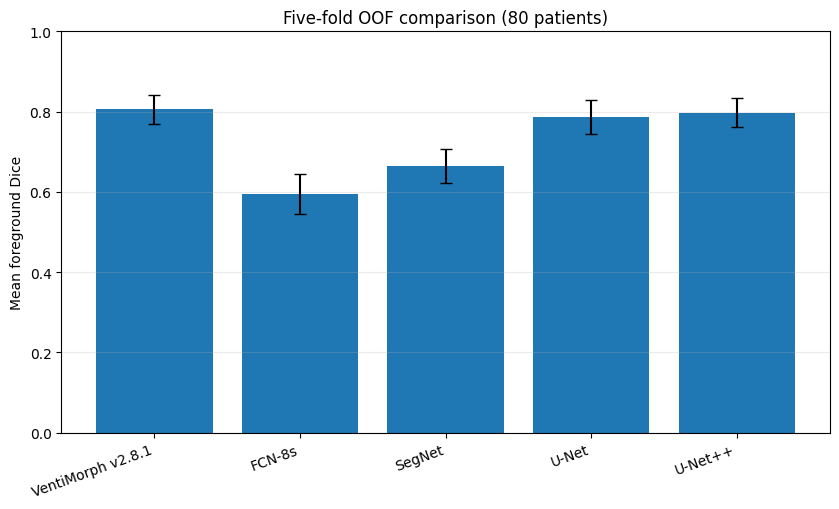

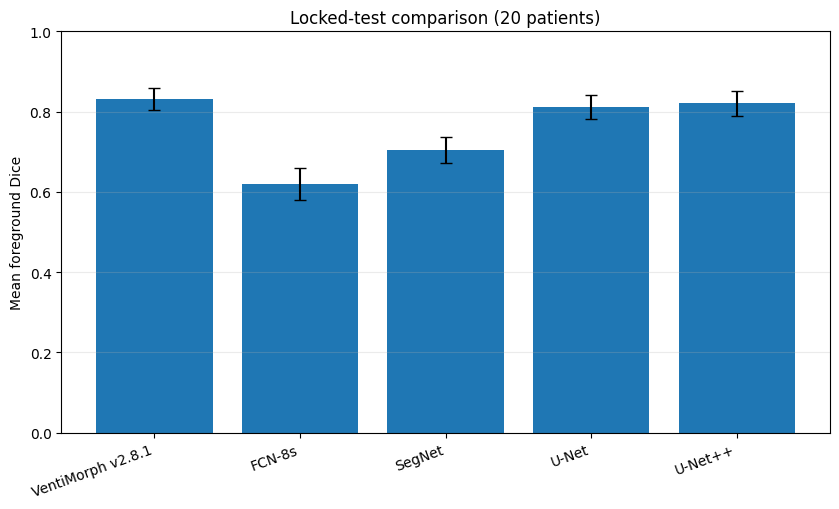

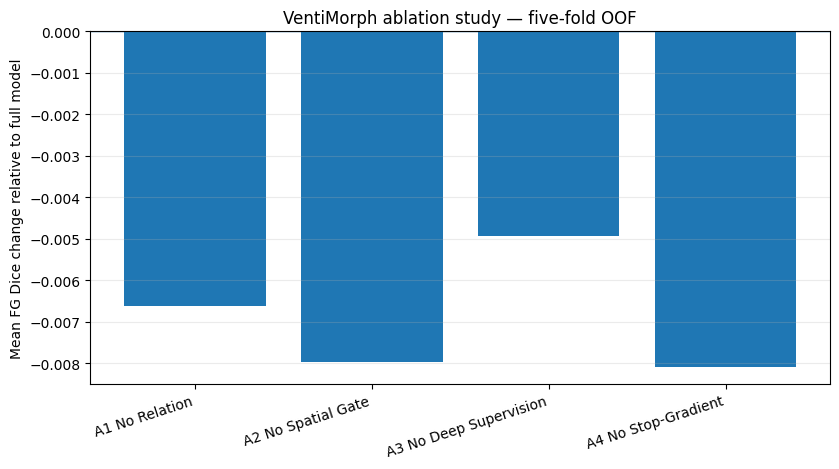

In [7]:

# Publication figure A: OOF baselines.
def mean_sd(df, metric):
    vals = pd.to_numeric(df[metric], errors="coerce")
    return float(vals.mean()), float(vals.std(ddof=1))

def comparison_bar(model_frames, title, filename):
    names = list(model_frames.keys())
    means = [mean_sd(model_frames[n], "mean_foreground_dice")[0] for n in names]
    sds = [mean_sd(model_frames[n], "mean_foreground_dice")[1] for n in names]
    x = np.arange(len(names))

    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.bar(x, means, yerr=sds, capsize=4)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel("Mean foreground Dice")
    ax.set_ylim(0, 1.0)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{filename}.pdf", bbox_inches="tight")
    plt.show()

comparison_bar(
    oof_frames,
    "Five-fold OOF comparison (80 patients)",
    "Figure_OOF_baseline_comparison",
)

comparison_bar(
    test_frames,
    "Locked-test comparison (20 patients)",
    "Figure_locked_test_baseline_comparison",
)

# Publication figure C: ablation delta.
full_mean = ablation_frames["Full VentiMorph"]["mean_foreground_dice"].mean()
abl_names = [
    "A1 No Relation",
    "A2 No Spatial Gate",
    "A3 No Deep Supervision",
    "A4 No Stop-Gradient",
]
deltas = [
    ablation_frames[name]["mean_foreground_dice"].mean() - full_mean
    for name in abl_names
]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(abl_names))
ax.bar(x, deltas)
ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(abl_names, rotation=18, ha="right")
ax.set_ylabel("Mean FG Dice change relative to full model")
ax.set_title("VentiMorph ablation study — five-fold OOF")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "Figure_ablation_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "Figure_ablation_comparison.pdf",
    bbox_inches="tight",
)
plt.show()


In [8]:

archive = shutil.make_archive(
    "/kaggle/working/MS3SEG_FINAL_JOURNAL_TABLES_FIGURES",
    "zip",
    root_dir=OUTPUT_DIR,
)
print("Download:", archive)


Download: /kaggle/working/MS3SEG_FINAL_JOURNAL_TABLES_FIGURES.zip
